In [ ]:
%pip install -q ultralytics

**mount**


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/nepal_vehicle_detection")
RAW = PROJECT / "datasets" / "raw/"
EXTRACTED = PROJECT / "datasets" / "extracted"
COMBINED = PROJECT / "datasets" / "combined/"

for folder in [RAW, EXTRACTED, COMBINED]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT)
print("ZIP files found:")

for f in sorted(RAW.glob("*.zip")):
    print(f.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder: /content/drive/MyDrive/nepal_vehicle_detection
ZIP files found:
car_detection.zip
car_object_detection.zip
vehicle_dataset_1.zip
vehicle_detection_count.zip
vehicle_object_recognition.zip
vehicles_dataset.zip


***extract***

In [ ]:
import zipfile

zip_files = sorted(RAW.glob("*.zip"))

if not zip_files:
    raise FileNotFoundError(
        f"No ZIP files found in {RAW}. Upload your six ZIP files first."
    )

for zip_path in zip_files:
    destination = EXTRACTED / zip_path.stem
    destination.mkdir(parents=True, exist_ok=True)

    if not any(destination.iterdir()):
        print("Extracting:", zip_path.name)

        with zipfile.ZipFile(zip_path, "r") as z:
            z.extractall(destination)
    else:
        print("Already extracted:", zip_path.name)

print("\nExtraction complete.")

Extracting: car_detection.zip
Extracting: car_object_detection.zip
Extracting: vehicle_dataset_1.zip
Extracting: vehicle_detection_count.zip
Extracting: vehicle_object_recognition.zip
Extracting: vehicles_dataset.zip

Extraction complete.


**identify class**

In [ ]:
import yaml

for dataset_folder in sorted(EXTRACTED.iterdir()):
    if not dataset_folder.is_dir():
        continue

    print("\n" + "=" * 60)
    print("DATASET:", dataset_folder.name)

    yaml_files = list(dataset_folder.rglob("data.yaml"))
    yaml_files += list(dataset_folder.rglob("data.yml"))

    if yaml_files:
        for yaml_file in yaml_files:
            try:
                with open(yaml_file, "r", encoding="utf-8") as f:
                    config = yaml.safe_load(f)

                print("\nYAML:", yaml_file)
                print("Classes:", config.get("names"))
                print("Train:", config.get("train"))
                print("Validation:", config.get("val"))
                print("Test:", config.get("test"))

            except Exception as e:
                print("Could not read YAML:", e)
    else:
        print("No data.yaml found.")

    print("\nImage and label folders:")
    for p in dataset_folder.rglob("*"):
        if p.is_dir() and p.name.lower() in {
            "images", "labels", "train", "valid", "val", "test"
        }:
            print(p.relative_to(dataset_folder))


DATASET: car_detection

YAML: /content/drive/MyDrive/nepal_vehicle_detection/datasets/extracted/car_detection/data.yaml
Classes: ['Bus', 'Car', 'Motorcycle', 'Pickup', 'Truck']
Train: ../train/images
Validation: ../valid/images
Test: ../test/images

Image and label folders:
test
train
valid
test/images
test/labels
train/images
train/labels
valid/images
valid/labels

DATASET: car_object_detection

YAML: /content/drive/MyDrive/nepal_vehicle_detection/datasets/extracted/car_object_detection/data.yaml
Classes: ['car']
Train: ../train/images
Validation: ../valid/images
Test: ../test/images

Image and label folders:
valid
train
test
valid/images
valid/labels
train/images
train/labels
test/images
test/labels

DATASET: vehicle_dataset_1

YAML: /content/drive/MyDrive/nepal_vehicle_detection/datasets/extracted/vehicle_dataset_1/data.yaml
Classes: ['auto rickshaw', 'bus', 'car', 'motorbike', 'truck']
Train: ../train/images
Validation: ../valid/images
Test: ../test/images

Image and label folders

**setup the path**

In [ ]:
from pathlib import Path
import yaml
import hashlib
import shutil
from collections import Counter, defaultdict

PROJECT = Path("/content/drive/MyDrive/nepal_vehicle_detection")
EXTRACTED = PROJECT / "datasets" / "extracted"
COMBINED = PROJECT / "datasets" / "combined"

# Standardized classes used by the final model
CLASS_NAMES = {
    0: "car",
    1: "motorcycle",
    2: "bus",
    3: "truck",
    4: "other_vehicle",
}

# Create the output folders
for split in ["train", "val", "test"]:
    (COMBINED / "images" / split).mkdir(parents=True, exist_ok=True)
    (COMBINED / "labels" / split).mkdir(parents=True, exist_ok=True)

print("Source:", EXTRACTED)
print("Destination:", COMBINED)
print("Datasets found:", [
    p.name for p in EXTRACTED.iterdir() if p.is_dir()
])

Source: /content/drive/MyDrive/nepal_vehicle_detection/datasets/extracted
Destination: /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined
Datasets found: ['car_detection', 'car_object_detection', 'vehicle_dataset_1', 'vehicle_detection_count', 'vehicle_object_recognition', 'vehicles_dataset']


**define class mapping**

In [ ]:
def map_class(class_name):
    name = str(class_name).strip().lower().replace("-", "_")
    name = " ".join(name.split())

    # Cars
    if name == "car":
        return 0

    # Motorcycles and scooters
    if name in {"motorcycle", "motorbike", "scooty", "scooter"}:
        return 1

    # Buses
    if name in {"bus", "large_bus"}:
        return 2

    # Trucks
    if (
        "truck" in name
        or name in {"lorry"}
    ):
        return 3

    # Other vehicle types
    if name in {
        "pickup", "van", "auto", "auto rickshaw",
        "rickshaw", "rickshow", "tractor"
    }:
        return 4

    # Ignore people, riders, bicycles, license plates, etc.
    return None

**merge class and annotation**

In [ ]:
import os

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Process test first, then validation, then training.
# This ensures exact duplicate images do not leak across splits.
SOURCE_SPLITS = [
    ("test", "test"),
    ("valid", "val"),
    ("val", "val"),
    ("train", "train"),
]

seen_hashes = set()
stats = defaultdict(Counter)
warnings = []

def load_class_names(yaml_path):
    with open(yaml_path, "r", encoding="utf-8") as f:
        cfg = yaml.safe_load(f) or {}

    names = cfg.get("names", {})
    if isinstance(names, list):
        return names
    if isinstance(names, dict):
        return [names[k] for k in sorted(names, key=lambda x: int(x))]
    raise ValueError(f"Unrecognized class names in {yaml_path}")

def find_split_dir(dataset_root, split_name):
    # Prefer the expected direct folder, e.g. dataset/train/images
    direct = dataset_root / split_name / "images"
    if direct.is_dir():
        return direct

    # Otherwise search nested folders
    matches = [
        p for p in dataset_root.rglob("images")
        if p.parent.name.lower() == split_name.lower()
    ]
    return matches[0] if matches else None

def get_label_path(image_path, images_dir):
    relative = image_path.relative_to(images_dir)
    return images_dir.parent / "labels" / relative.with_suffix(".txt")

def file_hash(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def remap_label_file(label_path, source_names):
    remapped = []

    if not label_path.is_file():
        return remapped

    with open(label_path, "r", encoding="utf-8") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) != 5:
                continue

            try:
                old_id = int(float(parts[0]))
                if not 0 <= old_id < len(source_names):
                    continue

                new_id = map_class(source_names[old_id])
                if new_id is None:
                    continue

                # Keep the normalized bounding-box coordinates unchanged
                coords = [float(v) for v in parts[1:]]
                if not all(0 <= v <= 1 for v in coords):
                    continue
                if coords[2] <= 0 or coords[3] <= 0:
                    continue

                remapped.append(
                    f"{new_id} " + " ".join(f"{v:.6f}" for v in coords)
                )
            except (ValueError, IndexError):
                continue

    return remapped

dataset_roots = [
    p for p in sorted(EXTRACTED.iterdir()) if p.is_dir()
]

if not dataset_roots:
    raise RuntimeError("No extracted dataset folders found.")

# First, make sure each dataset has a readable YAML file
dataset_info = {}

for root in dataset_roots:
    yaml_files = list(root.rglob("data.yaml")) + list(root.rglob("data.yml"))
    if not yaml_files:
        warnings.append(f"{root.name}: no data.yaml found; skipped")
        continue

    yaml_path = yaml_files[0]
    try:
        names = load_class_names(yaml_path)
        dataset_info[root] = (yaml_path, names)
        print(f"{root.name}: {names}")
    except Exception as e:
        warnings.append(f"{root.name}: failed to read YAML: {e}")

# Merge the sources
for source_split, output_split in SOURCE_SPLITS:
    for root, (_, source_names) in dataset_info.items():
        images_dir = find_split_dir(root, source_split)
        if images_dir is None:
            continue

        label_dir = images_dir.parent / "labels"
        image_paths = sorted(
            p for p in images_dir.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )

        for image_path in image_paths:
            stats[root.name]["images_seen"] += 1

            digest = file_hash(image_path)
            if digest in seen_hashes:
                stats[root.name]["duplicates_skipped"] += 1
                continue

            label_path = get_label_path(image_path, images_dir)
            if not label_path.is_file():
                stats[root.name]["missing_labels"] += 1
                continue

            new_labels = remap_label_file(label_path, source_names)
            if not new_labels:
                stats[root.name]["no_target_labels"] += 1
                continue

            # Prefix filenames with a content hash to avoid name collisions
            output_name = f"{digest[:16]}{image_path.suffix.lower()}"
            output_image = COMBINED / "images" / output_split / output_name
            output_label = COMBINED / "labels" / output_split / f"{digest[:16]}.txt"

            if output_image.exists() or output_label.exists():
                stats[root.name]["duplicates_skipped"] += 1
                continue

            shutil.copy2(image_path, output_image)
            output_label.write_text("\n".join(new_labels) + "\n", encoding="utf-8")

            seen_hashes.add(digest)
            stats[root.name]["images_merged"] += 1
            stats[root.name][f"{output_split}_images"] += 1

print("\nMerge complete.")
print("\nPer-dataset summary:")
for dataset_name, counts in sorted(stats.items()):
    print(dataset_name, dict(counts))

if warnings:
    print("\nWarnings:")
    for warning in warnings:
        print("-", warning)

car_detection: ['Bus', 'Car', 'Motorcycle', 'Pickup', 'Truck']
car_object_detection: ['car']
vehicle_dataset_1: ['auto rickshaw', 'bus', 'car', 'motorbike', 'truck']
vehicle_detection_count: ['bus', 'car', 'motorcycle', 'truck']
vehicle_object_recognition: ['-Medium_Trucks', 'Car', 'Large_Bus', 'Large_Trucks', 'Medium_Trucks_2', 'Small_Trucks', 'Van', 'person']
vehicles_dataset: ['auto', 'bicycle', 'bicycle-rider', 'bus', 'car', 'cattle', 'helmet', 'license_plate', 'lorry', 'motorbike', 'motorbike-rider', 'no_helmet', 'person', 'rickshow', 'scooty', 'scooty-rider', 'tractor', 'truck', 'vendor']

Merge complete.

Per-dataset summary:
car_detection {'images_seen': 175, 'images_merged': 175, 'test_images': 13, 'val_images': 28, 'train_images': 134}
car_object_detection {'images_seen': 2367, 'images_merged': 2361, 'test_images': 100, 'val_images': 200, 'train_images': 2061, 'duplicates_skipped': 6}
vehicle_dataset_1 {'images_seen': 3369, 'images_merged': 3369, 'test_images': 342, 'val_imag

**create data.yml file for yolov8**

In [ ]:
data_yaml = COMBINED / "data.yaml"

config = {
    "path": str(COMBINED),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": CLASS_NAMES,
}

with open(data_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(data_yaml.read_text())

path: /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined
train: images/train
val: images/val
test: images/test
names:
  0: car
  1: motorcycle
  2: bus
  3: truck
  4: other_vehicle



**chekc combined dataset**

In [ ]:
for split in ["train", "val", "test"]:
    image_dir = COMBINED / "images" / split
    label_dir = COMBINED / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]
    labels = list(label_dir.glob("*.txt"))

    print(
        f"{split:5} | images: {len(images):5} | "
        f"labels: {len(labels):5}"
    )

assert len(list((COMBINED / "images" / "train").glob("*"))) > 0, \
    "Training images are missing. Check the merge output."

print("\nDataset YAML:", data_yaml)

train | images:  5676 | labels:  5676
val   | images:  1243 | labels:  1243
test  | images:   759 | labels:   759

Dataset YAML: /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/data.yaml


**check the dataset before tranning**

In [ ]:
from pathlib import Path
from PIL import Image
from collections import Counter

DATASET = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/datasets/combined"
)

CLASS_NAMES = {
    0: "car",
    1: "motorcycle",
    2: "bus",
    3: "truck",
    4: "other_vehicle",
}

class_counts = Counter()
issues = []

for split in ["train", "val", "test"]:
    image_dir = DATASET / "images" / split
    label_dir = DATASET / "labels" / split

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    ]

    for image_path in images:
        label_path = label_dir / f"{image_path.stem}.txt"

        try:
            with Image.open(image_path) as im:
                im.verify()
        except Exception:
            issues.append(f"Unreadable image: {image_path.name}")
            continue

        if not label_path.exists():
            issues.append(f"Missing label: {image_path.name}")
            continue

        for line_no, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                cls = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                if cls not in CLASS_NAMES:
                    raise ValueError(f"Unknown class ID {cls}")

                if not all(0 <= v <= 1 for v in [x, y, w, h]):
                    raise ValueError("Coordinates outside 0-1")

                if w <= 0 or h <= 0:
                    raise ValueError("Invalid box width/height")

                class_counts[cls] += 1

            except Exception as e:
                issues.append(
                    f"{label_path.name}, line {line_no}: {e}"
                )

    print(f"{split}: {len(images)} images checked")

print("\nBounding boxes by class:")
for cls, name in CLASS_NAMES.items():
    print(f"{name}: {class_counts[cls]}")

print("\nIssues found:", len(issues))
for issue in issues[:20]:
    print("-", issue)

train: 5676 images checked
val: 1243 images checked
test: 759 images checked

Bounding boxes by class:
car: 54383
motorcycle: 4885
bus: 1714
truck: 1647
other_vehicle: 2049

Issues found: 0


**train yolov8**

In [ ]:
import ultralytics
import torch

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics version: 8.4.187
PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
from ultralytics import YOLO
import torch

# Dataset configuration path
DATA_YAML = "/content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/data.yaml"

# Load the YOLOv8 nano pretrained model
model = YOLO("yolov8n.pt")

# Train the vehicle detection model
results = model.train(
    data=DATA_YAML,
    epochs=30,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    patience=8,
    seed=42,
    project="/content/drive/MyDrive/nepal_vehicle_detection/runs",
    name="yolov8_vehicle_v1",
    plots=True,
    save=True
)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_vehicle_

In [ ]:
from ultralytics import YOLO
from pathlib import Path

MODEL_PATH = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "runs/yolov8_vehicle_v1/weights/best.pt"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"

best_model = YOLO(str(MODEL_PATH))

print("Best trained model loaded successfully!")
print("Classes:", best_model.names)

Best trained model loaded successfully!
Classes: {0: 'car', 1: 'motorcycle', 2: 'bus', 3: 'truck', 4: 'other_vehicle'}


In [ ]:
DATA_YAML = (
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "datasets/combined/data.yaml"
)

test_metrics = best_model.val(
    data=DATA_YAML,
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project="/content/drive/MyDrive/nepal_vehicle_detection/results",
    name="yolov8_vehicle_test"
)

print("\n===== TEST SET RESULTS =====")
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"mAP@50:     {test_metrics.box.map50:.4f}")
print(f"mAP@50-95:  {test_metrics.box.map:.4f}")

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.2 ms, read: 49.5±23.8 MB/s, size: 57.9 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/labels/test... 759 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 759/759 196.2it/s 3.9s
val: New cache created: /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 95/95 9.4it/s 10.1s
                   all        759       4070      0.862      0.839      0.889      0.653
                   car        608       3101       0.92      0.869      0.948      0.726
            mo

**check performance for each vehicle class**

In [ ]:
import pandas as pd

class_results = []

for class_id, class_name in best_model.names.items():
    class_results.append({
        "Class": class_name,
        "Precision": round(float(test_metrics.box.p[class_id]), 4),
        "Recall": round(float(test_metrics.box.r[class_id]), 4),
        "mAP@50": round(float(test_metrics.box.ap50[class_id]), 4),
        "mAP@50-95": round(float(test_metrics.box.ap[class_id]), 4)
    })

class_df = pd.DataFrame(class_results)
display(class_df)

,Class,Precision,Recall,mAP@50,mAP@50-95
0,car,0.9195,0.8693,0.9482,0.7259
1,motorcycle,0.8694,0.8235,0.8679,0.6007
2,bus,0.8367,0.8795,0.8982,0.6639
3,truck,0.7946,0.8730,0.8858,0.6528
4,other_vehicle,0.8892,0.7489,0.8469,0.6201


Selected 10 test images.

0: 640x640 19 cars, 1 motorcycle, 6.3ms
1: 640x640 19 cars, 9 motorcycles, 1 bus, 4 other_vehicles, 6.3ms
2: 640x640 25 cars, 6 motorcycles, 1 bus, 5 other_vehicles, 6.3ms
3: 640x640 31 cars, 2 other_vehicles, 6.3ms
4: 640x640 12 cars, 1 motorcycle, 1 other_vehicle, 6.3ms
5: 640x640 1 car, 1 truck, 6.3ms
6: 640x640 1 car, 1 truck, 6.3ms
7: 640x640 4 cars, 1 truck, 2 other_vehicles, 6.3ms
8: 640x640 31 cars, 2 motorcycles, 4 other_vehicles, 6.3ms
9: 640x640 22 cars, 2 motorcycles, 1 other_vehicle, 6.3ms
Speed: 1.4ms preprocess, 6.3ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/drive/MyDrive/nepal_vehicle_detection/results/sample_predictions-2
Image: e613b5563abe2cbb.jpg


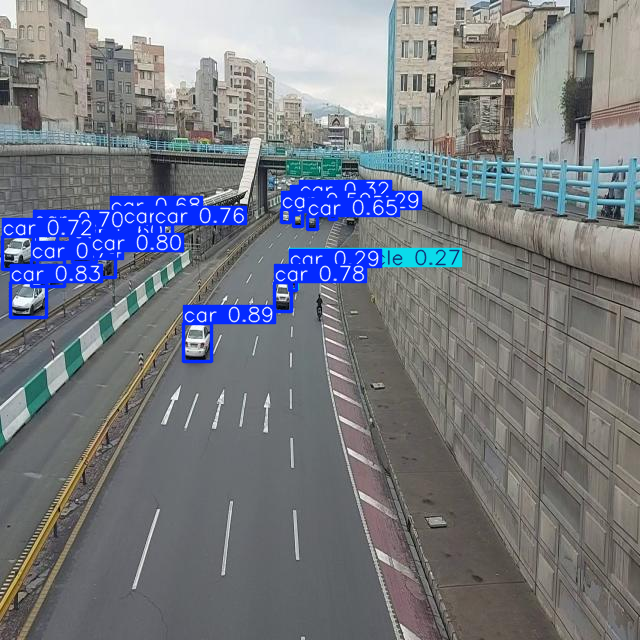

Image: 1a0b09c533aabceb.jpg


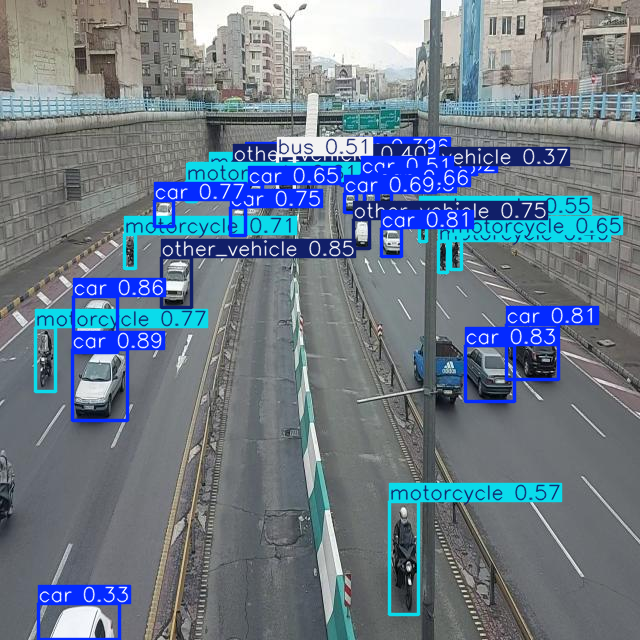

Image: 9797e021d31a4757.jpg


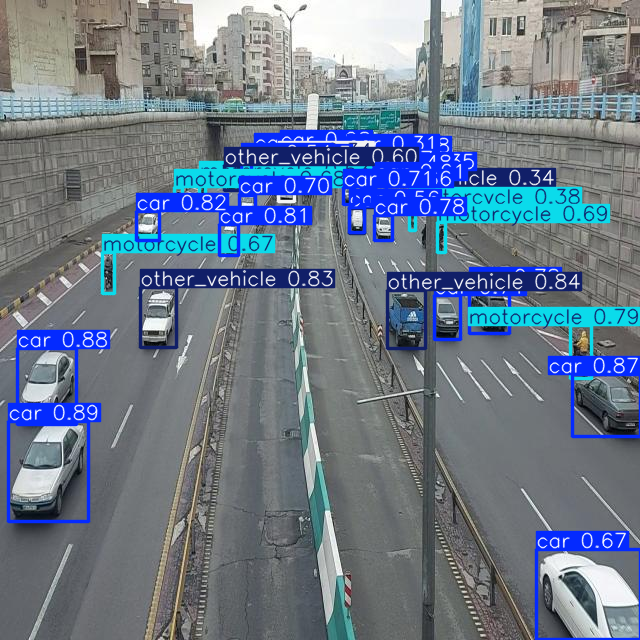

Image: 9b4b7e6e673906c7.jpg


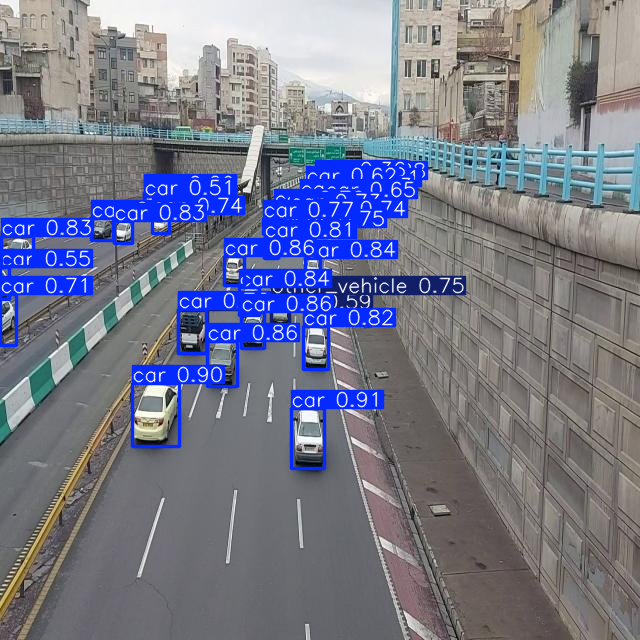

Image: 7e1b1e3c589a9b45.jpg


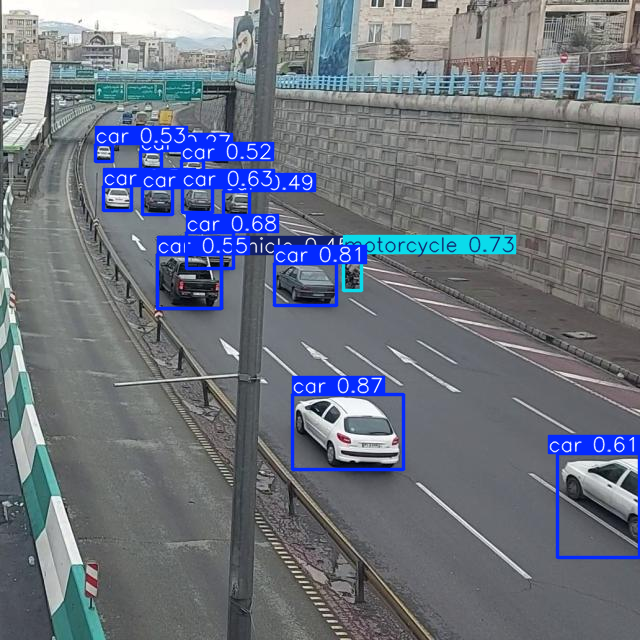

Image: 0eb988b15a9e0498.jpg


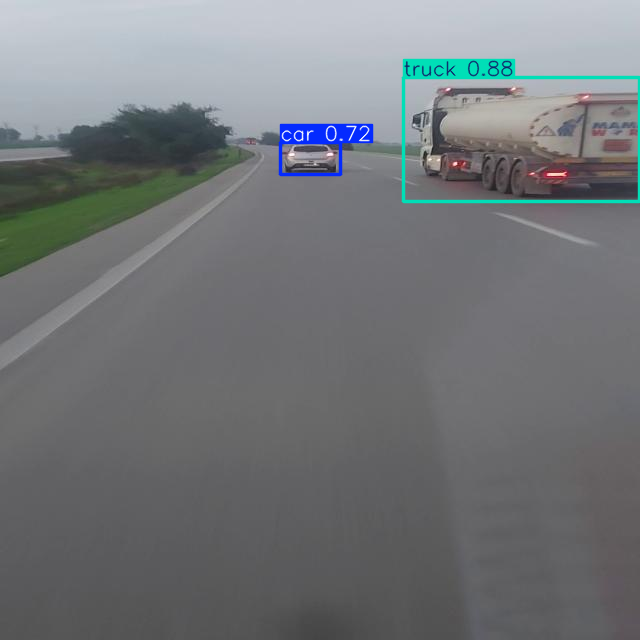

Image: fd119090a3a03c47.jpg


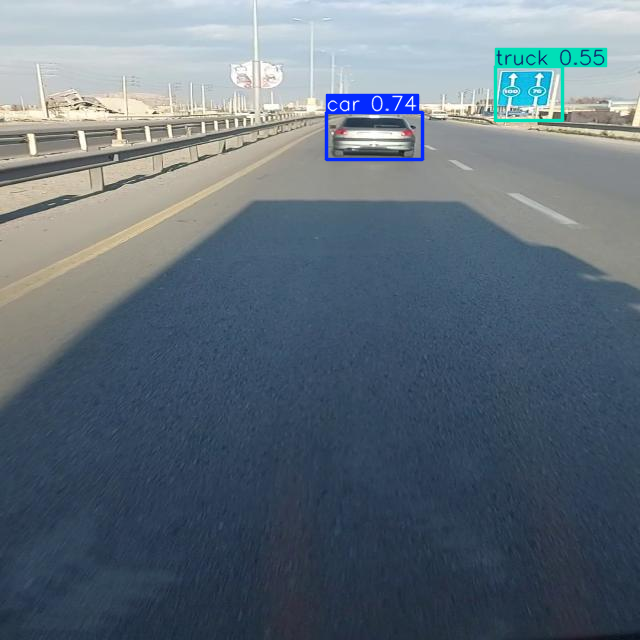

Image: 9411d3dcf1688ca1.jpg


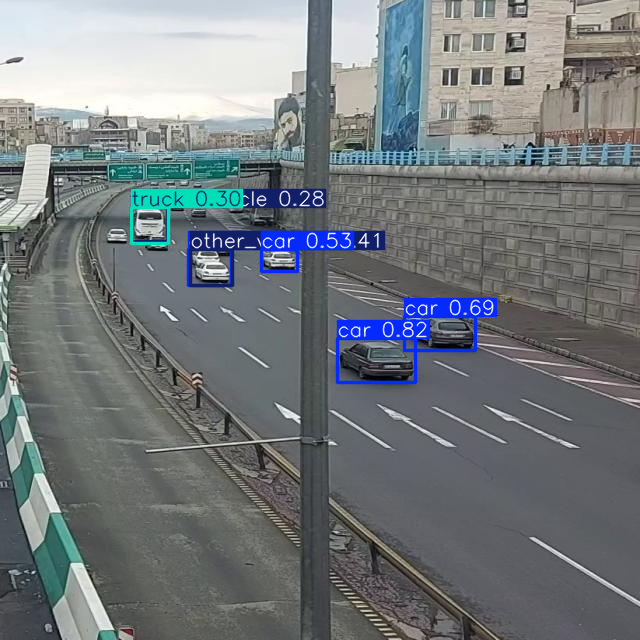

Image: bdaecb7e920b6c29.jpg


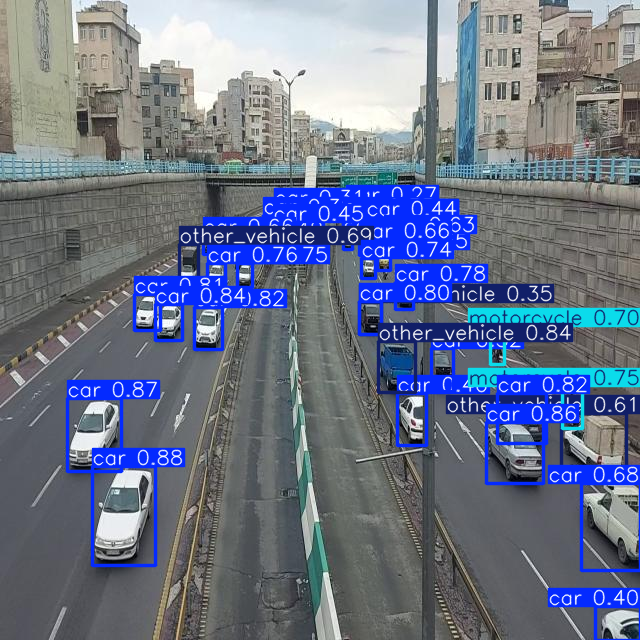

Image: d77831fabc38d427.jpg


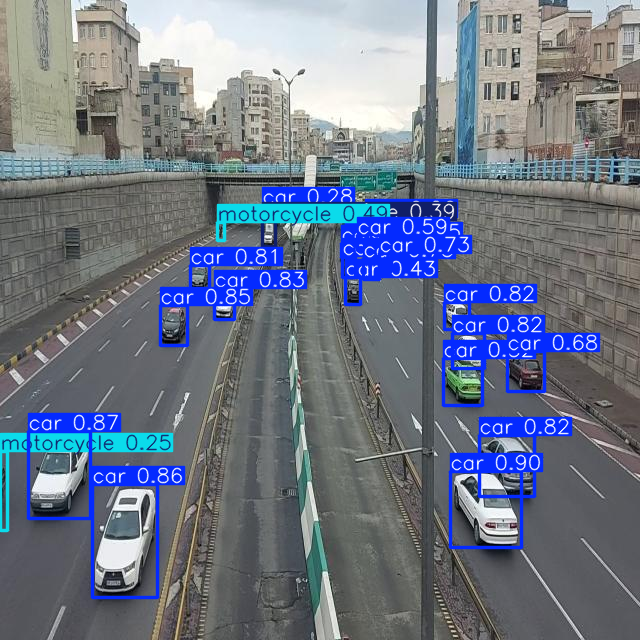


Prediction images saved successfully.
Folder: /content/drive/MyDrive/nepal_vehicle_detection/results/sample_predictions


In [ ]:

from pathlib import Path
from PIL import Image as PILImage
from IPython.display import display
from ultralytics import YOLO

# 1. Define the test image folder
TEST_IMAGES = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "datasets/combined/images/test"
)

# 2. Select the first 10 test images
sample_images = [
    p for p in TEST_IMAGES.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
][:10]

assert sample_images, f"No test images found in {TEST_IMAGES}"

print(f"Selected {len(sample_images)} test images.")

# 3. Load the trained model if it is not already loaded
MODEL_PATH = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "runs/yolov8_vehicle_v1/weights/best.pt"
)

assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
best_model = YOLO(str(MODEL_PATH))

# 4. Run vehicle detection
prediction_results = best_model.predict(
    source=[str(p) for p in sample_images],
    imgsz=640,
    conf=0.25,
    device=0,
    save=True,
    project="/content/drive/MyDrive/nepal_vehicle_detection/results",
    name="sample_predictions"
)

# 5. Display the images with predicted bounding boxes
for result in prediction_results:
    print("Image:", Path(result.path).name)

    # YOLO returns a BGR image; convert it to RGB
    plotted_image = result.plot()[:, :, ::-1]

    # Convert to a PIL image and display it
    display(PILImage.fromarray(plotted_image.copy()))

# 6. Confirm where the prediction images were saved
print("\nPrediction images saved successfully.")
print(
    "Folder:",
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "results/sample_predictions"
)


In [ ]:

from pathlib import Path
import pandas as pd
from ultralytics import YOLO

# 1. Define paths
BASE_DIR = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection"
)

DATA_YAML = BASE_DIR / "datasets/combined/data.yaml"

MODEL_PATH = (
    BASE_DIR
    / "runs/yolov8_vehicle_v1/weights/best.pt"
)

RESULTS_DIR = BASE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# 2. Load the best trained model
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert DATA_YAML.exists(), f"Dataset configuration not found: {DATA_YAML}"

best_model = YOLO(str(MODEL_PATH))

# 3. Evaluate on the test split
test_metrics = best_model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=640,
    batch=8,
    device=0,
    plots=True,
    project=str(RESULTS_DIR),
    name="yolov8_vehicle_test"
)

# 4. Display overall test results
print("\n===== YOLOv8 TEST RESULTS =====")
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"mAP@50:     {test_metrics.box.map50:.4f}")
print(f"mAP@50-95:  {test_metrics.box.map:.4f}")


Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.5±0.1 ms, read: 48.2±15.0 MB/s, size: 54.2 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/labels/test.cache... 759 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 759/759 122.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 95/95 9.9it/s 9.6s
                   all        759       4070      0.862      0.839      0.889      0.653
                   car        608       3101       0.92      0.869      0.948      0.726
            motorcycle        228        396      0.869      0.824      0.868      0.601
                   bus    

**save result**

In [ ]:

# Create a summary of the test results
summary = pd.DataFrame([{
    "Model": "YOLOv8n",
    "Epochs": 30,
    "Image Size": 640,
    "Precision": float(test_metrics.box.mp),
    "Recall": float(test_metrics.box.mr),
    "mAP@50": float(test_metrics.box.map50),
    "mAP@50-95": float(test_metrics.box.map)
}])

# Save the summary to Google Drive
csv_path = RESULTS_DIR / "test_metrics_summary.csv"
summary.to_csv(csv_path, index=False)

print("Test results:")
display(summary)

print("\nCSV saved to:", csv_path)


Test results:


,Model,Epochs,Image Size,Precision,Recall,mAP@50,mAP@50-95
0,YOLOv8n,30,640,0.861889,0.838849,0.889395,0.652672



CSV saved to: /content/drive/MyDrive/nepal_vehicle_detection/results/test_metrics_summary.csv


**check per class performance**

In [ ]:

class_results = []

for class_id, class_name in best_model.names.items():
    class_results.append({
        "Class": class_name,
        "Precision": round(float(test_metrics.box.p[class_id]), 4),
        "Recall": round(float(test_metrics.box.r[class_id]), 4),
        "mAP@50": round(float(test_metrics.box.ap50[class_id]), 4),
        "mAP@50-95": round(float(test_metrics.box.ap[class_id]), 4)
    })

class_df = pd.DataFrame(class_results)

display(class_df)

class_csv_path = RESULTS_DIR / "per_class_test_metrics.csv"
class_df.to_csv(class_csv_path, index=False)

print("Per-class results saved to:", class_csv_path)


,Class,Precision,Recall,mAP@50,mAP@50-95
0,car,0.9195,0.8693,0.9482,0.7259
1,motorcycle,0.8694,0.8235,0.8679,0.6007
2,bus,0.8367,0.8795,0.8982,0.6639
3,truck,0.7946,0.8730,0.8858,0.6528
4,other_vehicle,0.8892,0.7489,0.8469,0.6201


Per-class results saved to: /content/drive/MyDrive/nepal_vehicle_detection/results/per_class_test_metrics.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection"
)

paths_to_check = {
    "Best model": PROJECT / "runs/yolov8_vehicle_v1/weights/best.pt",
    "Last checkpoint": PROJECT / "runs/yolov8_vehicle_v1/weights/last.pt",
    "Test results folder": PROJECT / "results/yolov8_vehicle_test-2",
    "Prediction images": PROJECT / "results/sample_predictions",
}

for name, path in paths_to_check.items():
    print(f"\n{name}:")
    print("Path:", path)
    print("Exists:", path.exists())

    if path.is_dir():
        files = list(path.iterdir())
        print("Number of files:", len(files))
        for file in files[:10]:
            print(" -", file.name)


Best model:
Path: /content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/weights/best.pt
Exists: True

Last checkpoint:
Path: /content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/weights/last.pt
Exists: True

Test results folder:
Path: /content/drive/MyDrive/nepal_vehicle_detection/results/yolov8_vehicle_test-2
Exists: True
Number of files: 12
 - val_batch0_labels.jpg
 - val_batch0_pred.jpg
 - val_batch1_labels.jpg
 - val_batch1_pred.jpg
 - val_batch2_labels.jpg
 - val_batch2_pred.jpg
 - BoxPR_curve.png
 - BoxF1_curve.png
 - BoxP_curve.png
 - BoxR_curve.png

Prediction images:
Path: /content/drive/MyDrive/nepal_vehicle_detection/results/sample_predictions
Exists: True
Number of files: 10
 - e613b5563abe2cbb.jpg
 - 1a0b09c533aabceb.jpg
 - 9797e021d31a4757.jpg
 - 9b4b7e6e673906c7.jpg
 - 7e1b1e3c589a9b45.jpg
 - 0eb988b15a9e0498.jpg
 - fd119090a3a03c47.jpg
 - 9411d3dcf1688ca1.jpg
 - bdaecb7e920b6c29.jpg
 - d77831fabc38d427.jpg


In [ ]:
!pip install ultralytics==8.4.187

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 78.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO
from pathlib import Path

MODEL_PATH = (
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "runs/yolov8_vehicle_v1/weights/best.pt"
)

model = YOLO(MODEL_PATH)

print("Model loaded successfully!")
print("Vehicle classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded successfully!
Vehicle classes: {0: 'car', 1: 'motorcycle', 2: 'bus', 3: 'truck', 4: 'other_vehicle'}


In [ ]:
from pathlib import Path

RESULTS_DIR = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "results/yolov8_vehicle_test-2"
)

if RESULTS_DIR.exists():
    for file in sorted(RESULTS_DIR.rglob("*")):
        if file.is_file():
            print(file.relative_to(RESULTS_DIR))
else:
    print("Folder not found. Check the actual results folder name.")

BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg


In [ ]:
from pathlib import Path
import pandas as pd

PROJECT = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection"
)

csv_files = list(PROJECT.rglob("*.csv"))

print("CSV files found:", len(csv_files))

for path in csv_files:
    print(f"\n{'=' * 60}")
    print("File:", path)

    try:
        df = pd.read_csv(path)
        print(df.tail(5).to_string(index=False))
    except Exception as e:
        print("Could not read:", e)

CSV files found: 3

File: /content/drive/MyDrive/nepal_vehicle_detection/results/test_metrics_summary.csv
  Model  Epochs  Image Size  Precision   Recall   mAP@50  mAP@50-95
YOLOv8n      30         640   0.861889 0.838849 0.889395   0.652672

File: /content/drive/MyDrive/nepal_vehicle_detection/results/per_class_test_metrics.csv
        Class  Precision  Recall  mAP@50  mAP@50-95
          car     0.9195  0.8693  0.9482     0.7259
   motorcycle     0.8694  0.8235  0.8679     0.6007
          bus     0.8367  0.8795  0.8982     0.6639
        truck     0.7946  0.8730  0.8858     0.6528
other_vehicle     0.8892  0.7489  0.8469     0.6201

File: /content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/results.csv
 epoch    time  train/box_loss  train/cls_loss  train/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/dfl_loss   lr/pg0   lr/pg1   lr/pg2
    26 2659.24         0.85728         0.47151         0

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np

PROJECT = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection"
)

RESULTS_DIR = PROJECT / "results"

SUMMARY_CSV = RESULTS_DIR / "test_metrics_summary.csv"
CLASS_CSV = RESULTS_DIR / "per_class_test_metrics.csv"

assert SUMMARY_CSV.exists(), f"Missing file: {SUMMARY_CSV}"
assert CLASS_CSV.exists(), f"Missing file: {CLASS_CSV}"

overall_df = pd.read_csv(SUMMARY_CSV)
class_df = pd.read_csv(CLASS_CSV)

print("Overall test metrics:")
display(overall_df)

print("Per-class test metrics:")
display(class_df)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Overall test metrics:


,Model,Epochs,Image Size,Precision,Recall,mAP@50,mAP@50-95
0,YOLOv8n,30,640,0.861889,0.838849,0.889395,0.652672


Per-class test metrics:


,Class,Precision,Recall,mAP@50,mAP@50-95
0,car,0.9195,0.8693,0.9482,0.7259
1,motorcycle,0.8694,0.8235,0.8679,0.6007
2,bus,0.8367,0.8795,0.8982,0.6639
3,truck,0.7946,0.8730,0.8858,0.6528
4,other_vehicle,0.8892,0.7489,0.8469,0.6201


In [ ]:
# Overall precision and recall from the test summary
precision = float(overall_df.loc[0, "Precision"])
recall = float(overall_df.loc[0, "Recall"])

# Overall F1-score
overall_f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

# Per-class F1-scores
class_df["F1-score"] = (
    2 * class_df["Precision"] * class_df["Recall"]
    / (class_df["Precision"] + class_df["Recall"]).replace(0, np.nan)
).fillna(0)

# Macro averages: each class gets equal weight
macro_precision = class_df["Precision"].mean()
macro_recall = class_df["Recall"].mean()
macro_f1 = class_df["F1-score"].mean()

print("OVERALL TEST METRICS")
print(f"Precision:       {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall:          {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-score:        {overall_f1:.4f} ({overall_f1 * 100:.2f}%)")

print("\nMACRO-AVERAGED METRICS")
print(f"Macro precision: {macro_precision:.4f} ({macro_precision * 100:.2f}%)")
print(f"Macro recall:    {macro_recall:.4f} ({macro_recall * 100:.2f}%)")
print(f"Macro F1-score:  {macro_f1:.4f} ({macro_f1 * 100:.2f}%)")

print("\nPER-CLASS F1-SCORES")
display(
    class_df[["Class", "Precision", "Recall", "F1-score"]]
    .style.format({
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

OVERALL TEST METRICS
Precision:       0.8619 (86.19%)
Recall:          0.8388 (83.88%)
F1-score:        0.8502 (85.02%)

MACRO-AVERAGED METRICS
Macro precision: 0.8619 (86.19%)
Macro recall:    0.8388 (83.88%)
Macro F1-score:  0.8484 (84.84%)

PER-CLASS F1-SCORES


,Class,Precision,Recall,F1-score
0,car,0.9195,0.8693,0.8937
1,motorcycle,0.8694,0.8235,0.8458
2,bus,0.8367,0.8795,0.8576
3,truck,0.7946,0.8730,0.8320
4,other_vehicle,0.8892,0.7489,0.8130


In [ ]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "mAP@50",
        "mAP@50-95",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "Value": [
        precision,
        recall,
        overall_f1,
        float(overall_df.loc[0, "mAP@50"]),
        float(overall_df.loc[0, "mAP@50-95"]),
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

final_metrics["Percentage"] = final_metrics["Value"] * 100

display(
    final_metrics.style.format({
        "Value": "{:.4f}",
        "Percentage": "{:.2f}%"
    })
)

,Metric,Value,Percentage
0,Precision,0.8619,86.19%
1,Recall,0.8388,83.88%
2,F1-score,0.8502,85.02%
3,mAP@50,0.8894,88.94%
4,mAP@50-95,0.6527,65.27%
5,Macro Precision,0.8619,86.19%
6,Macro Recall,0.8388,83.88%
7,Macro F1-score,0.8484,84.84%


In [ ]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "mAP@50",
        "mAP@50-95",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "Value": [
        precision,
        recall,
        overall_f1,
        float(overall_df.loc[0, "mAP@50"]),
        float(overall_df.loc[0, "mAP@50-95"]),
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

final_metrics["Percentage"] = final_metrics["Value"] * 100

display(
    final_metrics.style.format({
        "Value": "{:.4f}",
        "Percentage": "{:.2f}%"
    })
)

,Metric,Value,Percentage
0,Precision,0.8619,86.19%
1,Recall,0.8388,83.88%
2,F1-score,0.8502,85.02%
3,mAP@50,0.8894,88.94%
4,mAP@50-95,0.6527,65.27%
5,Macro Precision,0.8619,86.19%
6,Macro Recall,0.8388,83.88%
7,Macro F1-score,0.8484,84.84%


In [ ]:
overall_output = RESULTS_DIR / "final_calculated_metrics.csv"
class_output = RESULTS_DIR / "final_per_class_metrics.csv"

final_metrics.to_csv(overall_output, index=False)
class_df.to_csv(class_output, index=False)

print("Files saved successfully:")
print(overall_output)
print(class_output)

Files saved successfully:
/content/drive/MyDrive/nepal_vehicle_detection/results/final_calculated_metrics.csv
/content/drive/MyDrive/nepal_vehicle_detection/results/final_per_class_metrics.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q ultralytics opencv-python

In [ ]:
from ultralytics import YOLO
from pathlib import Path

MODEL_PATH = (
    "/content/drive/MyDrive/nepal_vehicle_detection/"
    "runs/yolov8_vehicle_v1/weights/best.pt"
)

assert Path(MODEL_PATH).exists(), (
    f"Model not found: {MODEL_PATH}"
)

model = YOLO(MODEL_PATH)

print("Model loaded successfully!")
print("Vehicle classes:", model.names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Model loaded successfully!
Vehicle classes: {0: 'car', 1: 'motorcycle', 2: 'bus', 3: 'truck', 4: 'other_vehicle'}


In [ ]:
from google.colab import files

uploaded = files.upload()

video_name = next(iter(uploaded))
VIDEO_PATH = f"/content/{video_name}"

print("Uploaded video:", VIDEO_PATH)

Saving 1192116-hd_1920_1080_30fps.mp4 to 1192116-hd_1920_1080_30fps.mp4
Uploaded video: /content/1192116-hd_1920_1080_30fps.mp4


In [ ]:

from pathlib import Path
from ultralytics import YOLO

OUTPUT_DIR = "/content/vehicle_detection_results"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# Process the video using streaming inference
results = model.predict(
    source=VIDEO_PATH,
    conf=0.25,
    imgsz=640,
    stream=True,  # Prevent accumulating all results in RAM
    save=True,
    project=OUTPUT_DIR,
    name="detected_video",
    exist_ok=True,
    verbose=False
)

# Consume the generator so the entire video is processed
frame_count = 0

for result in results:
    frame_count += 1

    if frame_count % 100 == 0:
        print(f"Processed {frame_count} frames")

print("Detection complete!")
print(f"Frames processed: {frame_count}")
print("Output folder:", f"{OUTPUT_DIR}/detected_video")


NameError: name 'model' is not defined

In [ ]:

print("Video path:", VIDEO_PATH)
print("Video exists:", Path(VIDEO_PATH).exists())


NameError: name 'VIDEO_PATH' is not defined

In [ ]:
from google.colab import files

uploaded = files.upload()
video_name = next(iter(uploaded))
VIDEO_PATH = f"/content/{video_name}"

print("Video ready:", VIDEO_PATH)

Saving 1192116-hd_1920_1080_30fps.mp4 to 1192116-hd_1920_1080_30fps (1).mp4
Video ready: /content/1192116-hd_1920_1080_30fps (1).mp4


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/nepal_vehicle_detection")

print("Project folder exists:", ROOT.exists())
print("\nSaved model weights:")

for path in ROOT.glob("runs/yolov8_vehicle_v1/weights/*.pt"):
    print(path, f"({path.stat().st_size / (1024**2):.2f} MB)")

print("\nExisting models folder:")
models_folder = ROOT / "models"
if models_folder.exists():
    for path in models_folder.rglob("*"):
        if path.is_file():
            print(path.relative_to(ROOT))
else:
    print("The models folder has not been created yet.")


Mounted at /content/drive
Project folder exists: True

Saved model weights:
/content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/weights/best.pt (6.20 MB)
/content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/weights/last.pt (6.20 MB)

Existing models folder:


In [ ]:

from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/nepal_vehicle_detection")

paths_to_check = [
    ROOT / "runs/yolov8_vehicle_v1/weights/best.pt",
    ROOT / "runs/yolov8_vehicle_v1/weights/last.pt",
    ROOT / "datasets/combined/data.yaml",
    ROOT / "models/vehicle_detection"
]

for path in paths_to_check:
    if path.is_file():
        print(f"FOUND: {path} ({path.stat().st_size / (1024**2):.2f} MB)")
    elif path.is_dir():
        print(f"FOLDER EXISTS: {path}")
    else:
        print(f"NOT FOUND: {path}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
FOUND: /content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/weights/best.pt (6.20 MB)
FOUND: /content/drive/MyDrive/nepal_vehicle_detection/runs/yolov8_vehicle_v1/weights/last.pt (6.20 MB)
FOUND: /content/drive/MyDrive/nepal_vehicle_detection/datasets/combined/data.yaml (0.00 MB)
NOT FOUND: /content/drive/MyDrive/nepal_vehicle_detection/models/vehicle_detection


In [ ]:

from pathlib import Path
import shutil

ROOT = Path("/content/drive/MyDrive/nepal_vehicle_detection")

# Source files
WEIGHTS = ROOT / "runs/yolov8_vehicle_v1/weights"
DATA_YAML = ROOT / "datasets/combined/data.yaml"

# Destination folder
MODEL_DIR = ROOT / "models/vehicle_detection"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Copy trained weights
for filename in ["best.pt", "last.pt"]:
    source = WEIGHTS / filename
    if source.exists():
        shutil.copy2(source, MODEL_DIR / filename)
        print(f"Copied: {filename}")
    else:
        print(f"WARNING: {filename} not found")

# Copy dataset configuration
if DATA_YAML.exists():
    shutil.copy2(DATA_YAML, MODEL_DIR / "data.yaml")
    print("Copied: data.yaml")
else:
    print("WARNING: data.yaml not found")

print("\nModel files copied.")
print("Destination:", MODEL_DIR)


Copied: best.pt
Copied: last.pt
Copied: data.yaml

Model files copied.
Destination: /content/drive/MyDrive/nepal_vehicle_detection/models/vehicle_detection


In [ ]:

from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/models/vehicle_detection"
)

predict_code = r'''
from pathlib import Path
import argparse
from ultralytics import YOLO

MODEL_PATH = Path(__file__).parent / "best.pt"

def main():
    parser = argparse.ArgumentParser(
        description="Nepal Vehicle Detection using YOLOv8"
    )
    parser.add_argument(
        "--source", required=True,
        help="Image path, video path, or camera index such as 0"
    )
    parser.add_argument("--conf", type=float, default=0.25)
    parser.add_argument("--output", default="results")
    args = parser.parse_args()

    if not MODEL_PATH.exists():
        raise FileNotFoundError(f"Missing model: {MODEL_PATH}")

    model = YOLO(str(MODEL_PATH))

    print("Model loaded:", MODEL_PATH)
    print("Vehicle classes:", model.names)

    source = int(args.source) if args.source.isdigit() else args.source

    model.predict(
        source=source,
        conf=args.conf,
        save=True,
        project=args.output,
        name="predictions",
        exist_ok=True
    )

if __name__ == "__main__":
    main()
'''

(MODEL_DIR / "predict.py").write_text(predict_code.strip() + "\n")
print("Created predict.py")


Created predict.py


In [ ]:

from pathlib import Path

MODEL_DIR = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/models/vehicle_detection"
)

requirements = """ultralytics
opencv-python
"""

readme = """# Nepal Vehicle Detection Model

## Overview
A fine-tuned YOLOv8n object-detection model for vehicle detection.

## Classes
The model is intended to detect:
- car
- motorcycle
- bus
- truck
- other_vehicle

Check the loaded model's class names before deployment.

## Files
- best.pt: selected trained checkpoint for inference
- last.pt: checkpoint from the final training epoch
- data.yaml: dataset configuration used for training
- predict.py: command-line inference script
- requirements.txt: Python dependencies
- model_info.txt: model details

## Installation
Install Python and the required packages:

    pip install -r requirements.txt

## Run inference
For an image:

    python predict.py --source path/to/image.jpg

For a video:

    python predict.py --source path/to/video.mp4

For a camera:

    python predict.py --source 0

Optional confidence threshold:

    python predict.py --source path/to/image.jpg --conf 0.4

## Important
This model detects vehicles. It does not independently determine
whether a vehicle is illegally parked, track vehicles across frames,
or recognize license plates.

The dataset YAML may contain paths specific to the original
Google Drive environment. Update those paths if you use it elsewhere.
"""

model_info = """Project: Nepal Vehicle Detection
Architecture family: YOLOv8
Model variant: YOLOv8n
Task: Object detection
Image size used during training: 640
Training epochs: 30
Training seed: 42
Primary inference checkpoint: best.pt
Final-epoch checkpoint: last.pt

Intended classes:
car, motorcycle, bus, truck, other_vehicle

Note: This file records the known training configuration.
It is not a substitute for the original training logs or evaluation report.
"""

(MODEL_DIR / "requirements.txt").write_text(requirements)
(MODEL_DIR / "README.md").write_text(readme)
(MODEL_DIR / "model_info.txt").write_text(model_info)

print("Created README.md, requirements.txt, and model_info.txt")


Created README.md, requirements.txt, and model_info.txt


In [ ]:

from pathlib import Path
from ultralytics import YOLO

MODEL_DIR = Path(
    "/content/drive/MyDrive/nepal_vehicle_detection/models/vehicle_detection"
)

print("FINAL MODEL PACKAGE")
print("=" * 50)

for path in sorted(MODEL_DIR.iterdir()):
    if path.is_file():
        print(f"{path.name:20} {path.stat().st_size / (1024**2):.2f} MB")

# Test that the copied model loads
model = YOLO(str(MODEL_DIR / "best.pt"))

print("\nModel loaded successfully.")
print("Classes:", model.names)
print("\nPackage location:", MODEL_DIR)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
FINAL MODEL PACKAGE
README.md            0.00 MB
best.pt              6.20 MB
data.yaml            0.00 MB
last.pt              6.20 MB
model_info.txt       0.00 MB
predict.py           0.00 MB
requirements.txt     0.00 MB

Model loaded successfully.
Classes: {0: 'car', 1: 'motorcycle', 2: 'bus', 3: 'truck', 4: 'other_vehicle'}

Package location: /content/drive/MyDrive/nepal_vehicle_detection/models/vehicle_detection
